In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [62]:
df = pd.read_csv("C:/Users/adity/Downloads/uber.csv")

In [63]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

In [64]:
df = df.dropna()

In [65]:
df.head(10)

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
5,4.9,2011-02-12 02:27:09 UTC,-73.969019,40.755910,-73.969019,40.755910,1
6,24.5,2014-10-12 07:04:00 UTC,-73.961447,40.693965,-73.871195,40.774297,5
7,2.5,2012-12-11 13:52:00 UTC,0.000000,0.000000,0.000000,0.000000,1
8,9.7,2012-02-17 09:32:00 UTC,-73.975187,40.745767,-74.002720,40.743537,1
9,12.5,2012-03-29 19:06:00 UTC,-74.001065,40.741787,-73.963040,40.775012,1


In [66]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["dayofweek"] = df["pickup_datetime"].dt.dayofweek
df = df.drop(columns=["pickup_datetime"])

In [67]:
def haversine_distance(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    r = 6371  # Earth radius in kilometers
    return c * r

In [68]:
df["distance_km"] = haversine_distance(
    df["pickup_longitude"],
    df["pickup_latitude"],
    df["dropoff_longitude"],
    df["dropoff_latitude"]
)

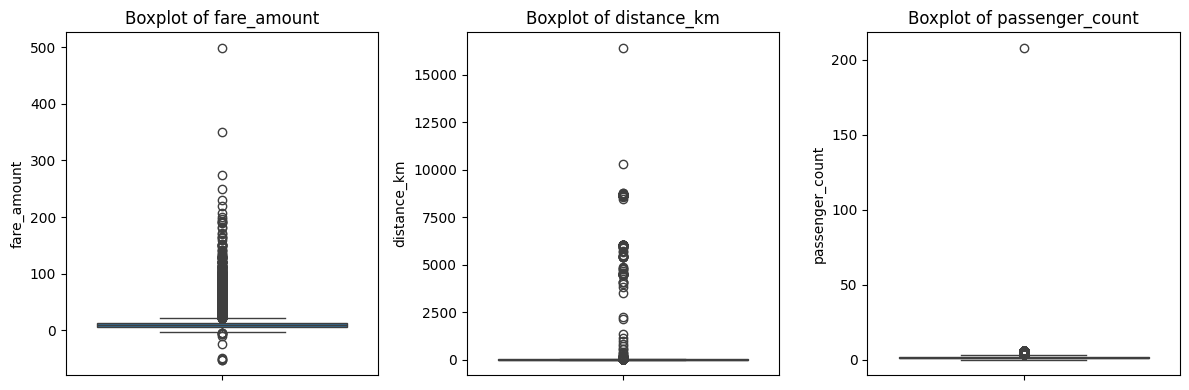

In [69]:
features_to_plot = ["fare_amount", "distance_km", "passenger_count"]
plt.figure(figsize=(12, 4))
for idx, col in enumerate(features_to_plot, 1):
    plt.subplot(1, 3, idx)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

In [70]:
# Filter unrealistic coordinate bounds and outliers
df = df[(df["pickup_latitude"] >= -90) & (df["pickup_latitude"] <= 90)]
df = df[(df["dropoff_latitude"] >= -90) & (df["dropoff_latitude"] <= 90)]
df = df[(df["pickup_longitude"] >= -180) & (df["pickup_longitude"] <= 180)]
df = df[(df["dropoff_longitude"] >= -180) & (df["dropoff_longitude"] <= 180)]

In [71]:
# Filter fare, distance, and passenger count
df = df[(df["fare_amount"] >= 2.5) & (df["fare_amount"] <= 100)]
df = df[(df["distance_km"] > 0) & (df["distance_km"] <= 100)]
df = df[(df["passenger_count"] >= 1) & (df["passenger_count"] <= 6)]

In [72]:
# 4. Check correlation
corr_matrix = df.corr()
print("Correlation Matrix:")
print(corr_matrix)

Correlation Matrix:
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.012177        -0.008993   
pickup_longitude      0.012177          1.000000        -0.993998   
pickup_latitude      -0.008993         -0.993998         1.000000   
dropoff_longitude     0.010719          0.999880        -0.993991   
dropoff_latitude     -0.008945         -0.993971         0.999926   
passenger_count       0.013694          0.009666        -0.009832   
hour                 -0.020688          0.001836        -0.000987   
day                   0.000843          0.019558        -0.020100   
month                 0.024683         -0.007513         0.008038   
year                  0.122803          0.013435        -0.014439   
dayofweek             0.004970          0.008241        -0.008961   
distance_km           0.858008          0.005568        -0.002343   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_am

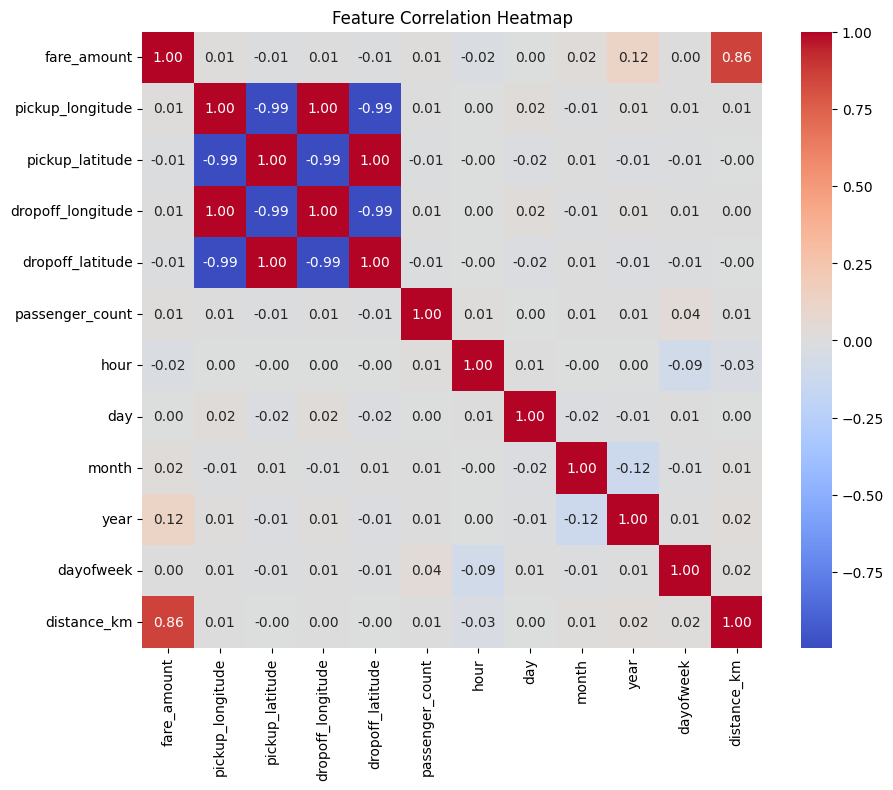

In [73]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [74]:
# 5. Distinguish features and target, split train/test
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [75]:
# 6. Linear Regression model
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [76]:
# 7. Random Forest Regression model
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [77]:
# 8. Evaluate and compare models
r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

In [78]:
print("\n--- Model Evaluation & Comparison ---")
print(f"Linear Regression       -> R2 Score: {r2_lr:.4f}, RMSE: {rmse_lr:.4f}")
print(f"Random Forest Regression -> R2 Score: {r2_rf:.4f}, RMSE: {rmse_rf:.4f}")


--- Model Evaluation & Comparison ---
Linear Regression       -> R2 Score: 0.7757, RMSE: 4.4644
Random Forest Regression -> R2 Score: 0.8710, RMSE: 3.3852
